In [3]:
# Name: Eshwar Lal
# Student ID: 023-24-0186
# Section: F
# Github: https://github.com/Eshwarlal-125/Machine_Learning_Course
# Kaggle: https://www.kaggle.com/mreshwar
# Dataset: Stroke Prediction Dataset 
# Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

In [ ]:
# Part: 0
# 1.	Install imbalanced-learn (pip install imbalanced-learn) and import everything you need.

# ! pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

In [27]:
# 2.	Load the CSV. Report the shape, the columns with missing values,
#  the value counts of gender and the number of patients with stroke = 1 
# and stroke = 0 (count and percentage).

df = pd.read_csv('healthcare-dataset-stroke-data_1.csv')

print("Shape:", df.shape)
display(df.head())
print("Missing Values: ", df.isnull().sum())
print("Gender Counts: ", df['gender'].value_counts())
print("Stroke Counts: ", df['stroke'].value_counts())
print("Stroke Percentages: ", df['stroke'].value_counts(normalize=True) * 100)
print("\nStroke Count and Percentage:")
stroke_summary = pd.DataFrame({
    'Count': df['stroke'].value_counts(),
    'Percentage': (df['stroke'].value_counts(normalize=True) * 100).round(2)
})
display(stroke_summary)

Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Missing Values:  id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
Gender Counts:  gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
Stroke Counts:  stroke
0    4861
1     249
Name: count, dtype: int64
Stroke Percentages:  stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

Stroke Count and Percentage:


,Count,Percentage
stroke,,
0,4861,95.13
1,249,4.87


In [29]:
# 3.	Clean the data: remove the identifier column; remove any gender category
# that has too few rows to learn or test; apply categorical encoding to the text
# columns (pd.get_dummies, as in the labs).df = df.drop(columns=['id'])

df = df.drop(columns=['id'])
print("Gender counts before cleaning:")
print(df['gender'].value_counts())
df = df[df['gender'] != 'Other'].copy()
df = pd.get_dummies(df, drop_first=True, dtype=int)
print("New Shape After Cleaning:", df.shape)
print("Remaining Columns:", df.columns.tolist())

display(df.head())


Gender counts before cleaning:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
New Shape After Cleaning: (5109, 16)
Remaining Columns: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,NaN,1,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,1,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1,0,1,0,0,1,0,0,0,1,0


In [30]:
# 4.	Split 80/20 with stratify=y and random_state=SEED. Fill the missing 
# numeric values with a median learned from the TRAIN set only. Create a scaled 
# copy (StandardScaler fitted on train) to use for Logistic Regression.

X = df.drop(columns=['stroke'])
y = df['stroke']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Training Missing Values:", X_train.isnull().sum().sum())
print("Testing Missing Values:", X_test.isnull().sum().sum())
print("Scaling Completed!")

Training Shape: (4087, 15)
Testing Shape: (1022, 15)
Training Missing Values: 0
Testing Missing Values: 0
Scaling Completed!


In [31]:
# 5.	Report how many stroke cases are in the training set and in the test set.

print("Stroke Cases in Training Set:", (y_train == 1).sum())
print("Stroke Cases in Test Set:", (y_test == 1).sum())

Stroke Cases in Training Set: 199
Stroke Cases in Test Set: 50


In [ ]:
# (a)In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, 
# and what could go wrong with only a few stroke cases in the test set?

# Answer:
# The data has many more non-stroke patients than stroke patients. 
# We used stratify=y to keep the same ratio in both sets. Otherwise, 
# testing results could be unreliable.

In [ ]:
# Part: 1
# 1.Build a baseline that always predicts the majority class (DummyClassifier, 
# strategy='most_frequent'). Report accuracy.

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
print("Baseline Accuracy:", baseline_accuracy)

# DummyClassifier always predicts the majority class (non-stroke patients).
# We use its accuracy as a baseline to compare with other models.

Baseline Accuracy: 0.9510763209393346


In [ ]:
# 2.	Train a default Logistic Regression on the scaled training data. 
# Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) 
# on the test set, and plot or print its confusion matrix.

lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print("PR AUC:", average_precision_score(y_test, y_prob))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# fit() trains Logistic Regression.
# predict() predicts stroke (0 or 1).
# predict_proba() gives stroke probabilities.
# The six metrics evaluate model performance.
# Confusion Matrix shows correct and incorrect predictions.

Accuracy: 0.952054794520548
Precision: 1.0
Recall: 0.02
F1 Score: 0.0392156862745098
ROC AUC: 0.8394238683127573
PR AUC: 0.2692194490111673
Confusion Matrix:
[[972   0]
 [ 49   1]]


In [34]:
# 3.Write a small helper function that takes a model and train/test data and 
# returns these six metrics - you will reuse it all lab.

def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }
print("Helper Function Created Successfully!")

Helper Function Created Successfully!


(a)	Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

-- The baseline gives high accuracy by always predicting non-stroke patients. Logistic Regression performs better at identifying stroke cases, so accuracy alone is not enough to judge the model.

(b)	Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

--A false negative means the model predicts a patient has no stroke risk when they actually had a stroke. This is dangerous in a hospital. We should focus on Recall, Precision, F1-score and PR AUC instead of accuracy because missing stroke patients is costly.

In [35]:
# Part: 2     Task: 2.1
# # 1.	For max_depth = 1, 2, ..., 15 and None, record the train ROC AUC and 
# the 5-fold stratified cross-validation ROC AUC (train data only).
from sklearn.model_selection import cross_validate, StratifiedKFold
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring='roc_auc',
        return_train_score=True
    )
    results.append({
        'Max Depth': str(depth),
        'Train ROC AUC': scores['train_score'].mean(),
        'CV ROC AUC': scores['test_score'].mean()
    })
results_df = pd.DataFrame(results)
display(results_df)
print("Best Depth:", results_df.loc[results_df['CV ROC AUC'].idxmax(), 'Max Depth'])
print("Best CV ROC AUC:", results_df['CV ROC AUC'].max())

,Max Depth,Train ROC AUC,CV ROC AUC
0,1,0.752304,0.731666
1,2,0.828284,0.816755
2,3,0.847048,0.816109
3,4,0.865828,0.818040
4,5,0.889965,0.792089
5,6,0.914956,0.758513
6,7,0.937748,0.738470
7,8,0.957291,0.713760
8,9,0.974830,0.681188
9,10,0.987531,0.641388


Best Depth: 4
Best CV ROC AUC: 0.8180403159452002


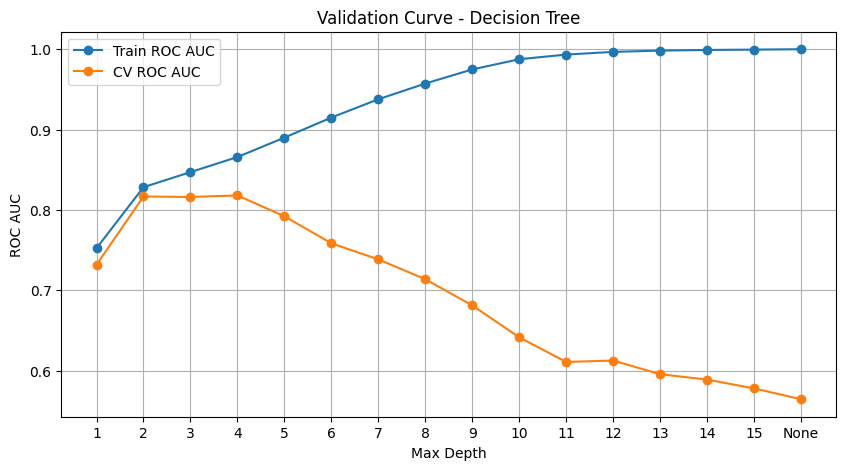

Best Depth: 4
Best CV ROC AUC: 0.818


In [ ]:
# 2.	Plot both curves on one chart (labelled axes, title, legend).
# Report the best depth by CV AUC.

plt.figure(figsize=(10, 5))
plt.plot(results_df['Max Depth'], results_df['Train ROC AUC'], 
         marker='o', label='Train ROC AUC')
plt.plot(results_df['Max Depth'], results_df['CV ROC AUC'],
         marker='o', label='CV ROC AUC')
plt.xlabel("Max Depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve - Decision Tree")
plt.legend()
plt.grid(True)
plt.show()
best_depth = results_df.loc[results_df['CV ROC AUC'].idxmax(), 'Max Depth']
best_auc = results_df['CV ROC AUC'].max()
print("Best Depth:", best_depth)
print("Best CV ROC AUC:", round(best_auc, 4))

# The best depth is 4, with a CV ROC AUC of approximately 0.819. 
# It gives the best performance on unseen data compared to other depths.

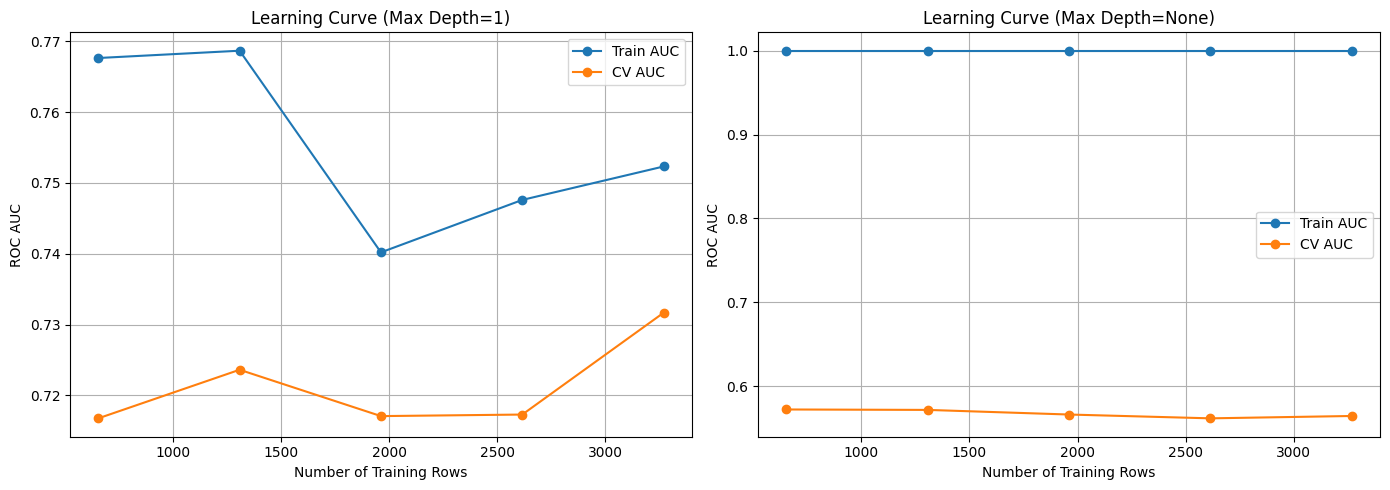

In [37]:
# Task: 2.2
# 1.	Use sklearn.model_selection.learning_curve (scoring='roc_auc', train_sizes 
# from 20% to 100%) for a tree with max_depth=1 and a tree with max_depth=None. 
# Plot train and CV AUC against the number of training rows, side by side.

from sklearn.model_selection import learning_curve
train_sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, depth in enumerate([1, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    sizes, train_scores, cv_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring='roc_auc',
        random_state=SEED
    )
    axes[i].plot(sizes, train_scores.mean(axis=1),
                 marker='o', label='Train AUC')
    axes[i].plot(sizes, cv_scores.mean(axis=1),
                 marker='o', label='CV AUC')
    axes[i].set_title(f'Learning Curve (Max Depth={depth})')
    axes[i].set_xlabel("Number of Training Rows")
    axes[i].set_ylabel("ROC AUC")
    axes[i].legend()
    axes[i].grid(True)
plt.tight_layout()
plt.show()

In [38]:
# Task: 2.3
# 1.   For each of max_depth = 1, 3 and None: draw 40 bootstrap samples of the TRAIN rows 
# (sample with replacement, same size), fit a tree on each, and collect each tree's predicted stroke 
# probability for every test patient.

rng = np.random.default_rng(SEED)
depths = [1, 3, None]
bootstrap_predictions = {}
for depth in depths:
    probs = []
    for i in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        )
        model.fit(X_boot, y_boot)
        y_prob = model.predict_proba(X_test)[:, 1]
        probs.append(y_prob)
    bootstrap_predictions[depth] = np.array(probs)
    print(f"Depth {depth}: Predictions Shape =",
          bootstrap_predictions[depth].shape)

Depth 1: Predictions Shape = (40, 1022)
Depth 3: Predictions Shape = (40, 1022)
Depth None: Predictions Shape = (40, 1022)


In [41]:
# 2.For every test patient, compute the variance of its 40 predicted probabilities; 
# then average over patients. Also report the mean test ROC AUC of the 40 trees and the 
# ROC AUC of the averaged prediction (mean of the 40 probability vectors).

variance_results = []
for depth in depths:
    probs = bootstrap_predictions[depth]
    patient_variance = probs.var(axis=0)
    avg_variance = patient_variance.mean()
    auc_scores = [roc_auc_score(y_test, prob) for prob in probs]
    mean_auc = np.mean(auc_scores)
    avg_predictions = probs.mean(axis=0)
    avg_auc = roc_auc_score(y_test, avg_predictions)
    variance_results.append({
        'Max Depth': str(depth),
        'Average Variance': avg_variance,
        'Mean Test ROC AUC': mean_auc,
        'Averaged Prediction ROC AUC': avg_auc
    })

In [42]:
# 3.Show the three depths in one table.
variance_df = pd.DataFrame(variance_results)
display(variance_df.round(4))

,Max Depth,Average Variance,Mean Test ROC AUC,Averaged Prediction ROC AUC
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7964,0.8343
2,None,0.0420,0.5552,0.7566


(a)	From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.
(b)	From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?
(c)	From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).
(d)	In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

(a): Depth 1 underfits because the model is too simple. Depths 5 and above start overfitting. I would choose depth 4 because it gives the best CV AUC (approximately 0.819), with train AUC around 0.87.

(b): High bias means both train and CV scores are low. High variance means training score is high but CV score is lower. Adding more data can reduce variance, but usually cannot fix high bias completely.

(c): Variance generally increases with tree depth because deeper trees are more sensitive to training data changes. Averaging predictions makes results more stable and can improve AUC. Random Forest uses the same idea by combining multiple trees.

(d): It means balancing a model that is too simple or too complex. Depth 1 has high bias, depth 3 gives a better balance, and depth None has high variance and can overfit.

In [43]:
# Part: 3       Task: 3.1
# 1.Train Logistic Regression (scaled), Decision Tree (max_depth=3) and Random Forest (200 trees,
# min_samples_leaf=5, random_state=SEED) on the original training data.

lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)
dt = DecisionTreeClassifier(max_depth=3, random_state=SEED)
dt.fit(X_train, y_train)
rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)
rf.fit(X_train, y_train)
print("Logistic Regression Trained Successfully!")
print("Decision Tree Trained Successfully!")
print("Random Forest Trained Successfully!")

Logistic Regression Trained Successfully!
Decision Tree Trained Successfully!
Random Forest Trained Successfully!


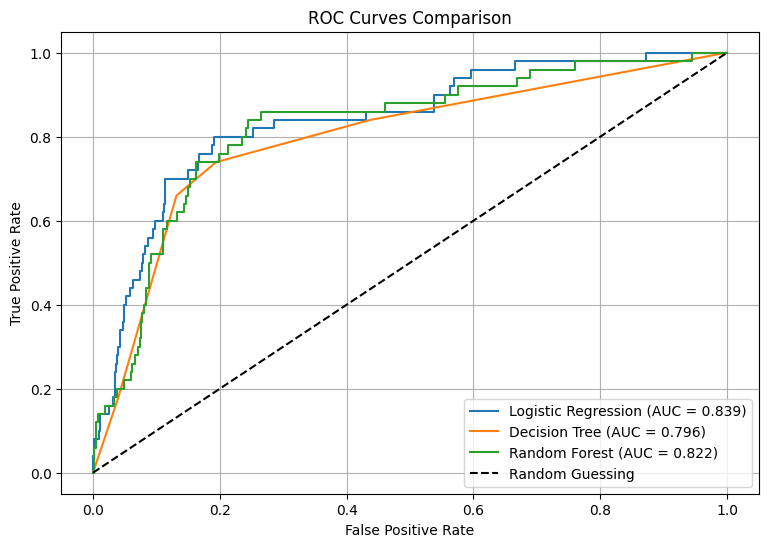

In [46]:
# 2.Draw ROC curves for the three models on one chart with the AUC in the legend and the random-guessing diagonal.

models = {
    'Logistic Regression': (lr, X_test_scaled),
    'Decision Tree': (dt, X_test),
    'Random Forest': (rf, X_test)
}
plt.figure(figsize=(9, 6))
for name, (model, X_data) in models.items():
    y_prob = model.predict_proba(X_data)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 3.Draw Precision-Recall curves for the same models on a second chart. Add a horizontal 
# line at the no-skill level (the stroke rate) and put the average precision in the legend.

models = {
    'Logistic Regression': (lr, X_test_scaled),
    'Decision Tree': (dt, X_test),
    'Random Forest': (rf, X_test)
}

plt.figure(figsize=(9, 6))

for name, (model, X_data) in models.items():

    y_prob = model.predict_proba(X_data)[:, 1]

    precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)

    plt.plot(recall, precision, label=f'{name} (AP = {ap:.3f})')

stroke_rate = y_test.mean()

plt.axhline(stroke_rate, linestyle='--',
            color='black', label=f'No-Skill Level ({stroke_rate:.3f})')

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves Comparison")
plt.legend()
plt.grid(True)
plt.show()